In [1]:
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

sys.path.append("..")                      # lets the notebook import from the src folder
from src import preprocessing as pp

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/loans_clean.csv", parse_dates=["IssueDate"])
print(df.shape)

(1347681, 11)


In [2]:
dti = df["DTI"]
for limit in [40, 60, 100]:
    print(f"DTI above {limit}: {(dti > limit).sum():,}")
print("DTI equal to 999:", (dti == 999).sum())
print("Largest values:", sorted(dti.dropna().unique())[-5:])
print("Default rate where DTI is above 100:", round(df.loc[dti > 100, "Default"].mean(), 3))

DTI above 40: 6,804
DTI above 60: 1,718
DTI above 100: 533
DTI equal to 999: 38
Largest values: [np.float64(831.97), np.float64(879.55), np.float64(886.77), np.float64(991.57), np.float64(999.0)]
Default rate where DTI is above 100: 0.268


In [3]:
df["IssueMonth"] = df["IssueDate"].dt.month
df["LoanToIncome"] = df["LoanAmount"] / df["Income"]
df["EmploymentMissing"] = df["EmploymentLength"].isna()

df[["IssueYear", "IssueMonth", "LoanToIncome"]].describe().round(3)

,IssueYear,IssueMonth,LoanToIncome
count,1347681.000,1347681.000,1347681.000
mean,2014.959,6.509,0.211
std,1.662,3.450,0.112
min,2007.000,1.000,0.000
25%,2014.000,3.000,0.123
50%,2015.000,7.000,0.197
75%,2016.000,10.000,0.286
max,2018.000,12.000,1.338


In [4]:
features = pp.prepare_features(df)
print("DTI values turned into missing:", features["DTI"].isna().sum() - df["DTI"].isna().sum())

preprocessor = pp.build_preprocessor()
X = preprocessor.fit_transform(features).astype("float32")
feature_names = list(preprocessor.get_feature_names_out())

print("Matrix shape:", X.shape)
print(feature_names)

DTI values turned into missing: 533
Matrix shape: (1347681, 15)
['Income', 'LoanAmount', 'DTI', 'CreditScore', 'EmploymentLength', 'Purpose_credit_card', 'Purpose_debt_consolidation', 'Purpose_home_improvement', 'Purpose_major_purchase', 'Purpose_other', 'Purpose_infrequent_sklearn', 'HomeOwnership_mortgage', 'HomeOwnership_own', 'HomeOwnership_rent', 'HomeOwnership_infrequent_sklearn']


In [5]:
X_frame = pd.DataFrame(X, columns=feature_names)
numeric_names = pp.LOG_COLUMNS + pp.PLAIN_NUMERIC_COLUMNS

print(X_frame[numeric_names].agg(["mean", "std", "min", "max"]).round(2).T)
print("\nSkewness before:", df[["Income", "LoanAmount"]].skew().round(2).to_dict())
print("Skewness after: ", X_frame[["Income", "LoanAmount"]].skew().round(2).to_dict())
print("Missing values left:", int(np.isnan(X).sum()))

                  mean  std   min   max
Income            -0.0  1.0 -2.40  2.64
LoanAmount        -0.0  1.0 -2.98  1.59
DTI               -0.0  1.0 -1.94  2.40
CreditScore        0.0  1.0 -1.15  3.31
EmploymentLength  -0.0  1.0 -1.66  1.13

Skewness before: {'Income': 45.4, 'LoanAmount': 0.78}
Skewness after:  {'Income': 0.10999999940395355, 'LoanAmount': -0.5899999737739563}
Missing values left: 0


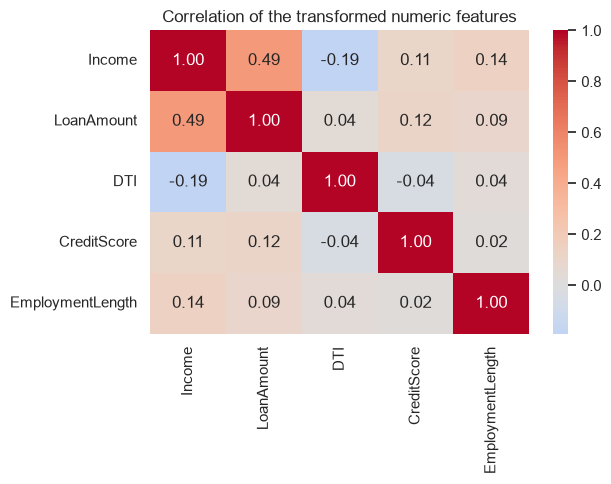

In [6]:
sample = X_frame[numeric_names].sample(200_000, random_state=1)

plt.figure(figsize=(6.5, 5))
sns.heatmap(sample.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of the transformed numeric features")
plt.tight_layout()
plt.savefig("../docs/figures/09_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

Components needed for 80% of the variance: 4
Components needed for 90% of the variance: 5
Components needed for 95% of the variance: 6


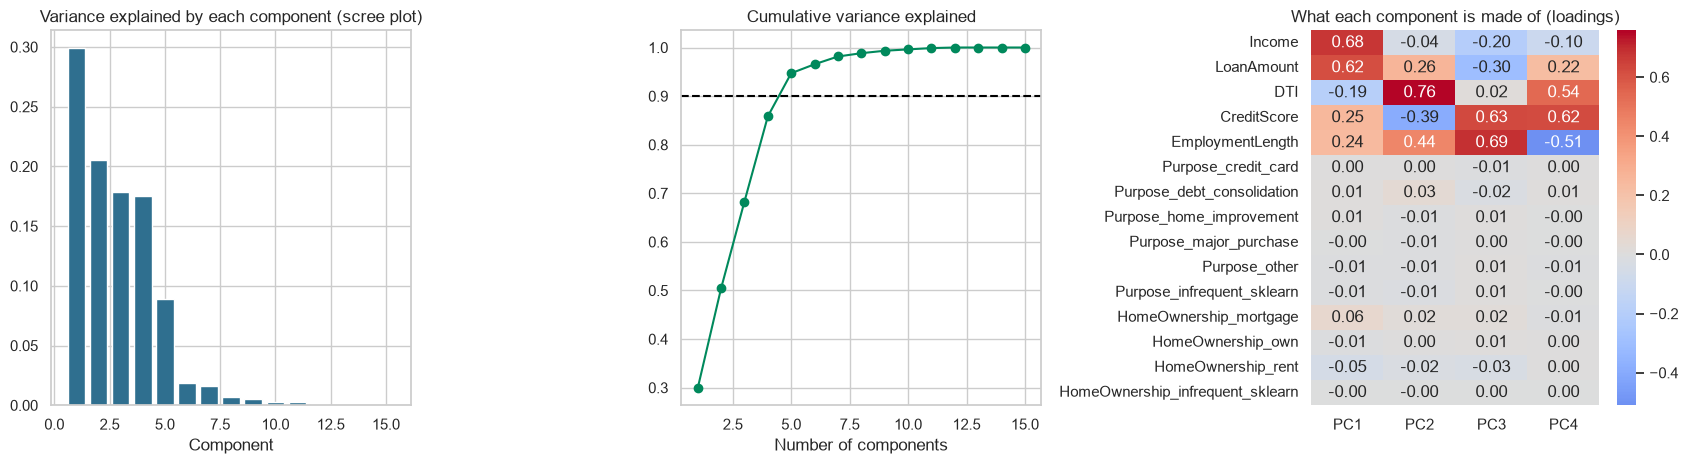

In [7]:
pca = PCA(random_state=42).fit(X)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

for share in (0.80, 0.90, 0.95):
    print(f"Components needed for {share:.0%} of the variance:", int(np.argmax(cumulative >= share)) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].bar(range(1, len(explained) + 1), explained, color="#2F6F8F")
axes[0].set_title("Variance explained by each component (scree plot)")
axes[0].set_xlabel("Component")

axes[1].plot(range(1, len(cumulative) + 1), cumulative, marker="o", color="#00895C")
axes[1].axhline(0.90, color="black", linestyle="--")
axes[1].set_title("Cumulative variance explained")
axes[1].set_xlabel("Number of components")

loadings = pd.DataFrame(pca.components_[:4].T, index=feature_names, columns=["PC1", "PC2", "PC3", "PC4"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("What each component is made of (loadings)")

plt.tight_layout()
plt.savefig("../docs/figures/10_pca_variance.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
N_COMPONENTS = int(np.argmax(cumulative >= 0.90)) + 1
X_pca = pca.transform(X)[:, :N_COMPONENTS].astype("float32")

print(f"Keeping {N_COMPONENTS} components, explaining {cumulative[N_COMPONENTS - 1]:.1%} of the variance")
print("PCA matrix shape:", X_pca.shape)

Keeping 5 components, explaining 94.7% of the variance
PCA matrix shape: (1347681, 5)


In [9]:
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X), size=20_000, replace=False)     # first 10,000 of these = a 10,000 sample
print(sample_idx[:5], len(set(sample_idx)))

[1305590  105296  963474  581608  402040] 20000


In [10]:
joblib.dump(preprocessor, "../models/preprocessor.joblib")
joblib.dump(pca, "../models/pca.joblib")
np.save("../data/processed/X_scaled.npy", X)
np.save("../data/processed/X_pca.npy", X_pca)
np.save("../data/processed/sample_idx.npy", sample_idx)

with open("../models/feature_info.json", "w") as file:
    json.dump({"feature_names": feature_names, "n_components": N_COMPONENTS,
               "variance_explained": float(cumulative[N_COMPONENTS - 1])}, file, indent=2)
print("Saved preprocessor, PCA, matrices and sample positions")

Saved preprocessor, PCA, matrices and sample positions


In [11]:
reloaded = joblib.load("../models/preprocessor.joblib")

# 1. The reloaded pipeline must reproduce the stored rows exactly
check = reloaded.transform(pp.prepare_features(df.iloc[:5]))
assert np.allclose(check, X[:5], atol=1e-5), "reloaded pipeline gives different numbers"

# 2. A brand-new borrower, including a purpose never seen before, must also work
new_borrower = pd.DataFrame([{
    "Income": 60000, "DTI": 18, "LoanAmount": 12000, "CreditScore": 700,
    "EmploymentLength": np.nan, "Purpose": "never_seen_before", "HomeOwnership": "rent",
}])
new_row = reloaded.transform(pp.prepare_features(new_borrower))
print("New borrower:", new_row.shape, "| missing values:", int(np.isnan(new_row).sum()))
print("All checks passed")

New borrower: (1, 15) | missing values: 0
All checks passed
